In [1]:

import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))



PyTorch version: 2.11.0+cu128
OpenCV version: 4.13.0
NumPy version: 2.3.2
GPU available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


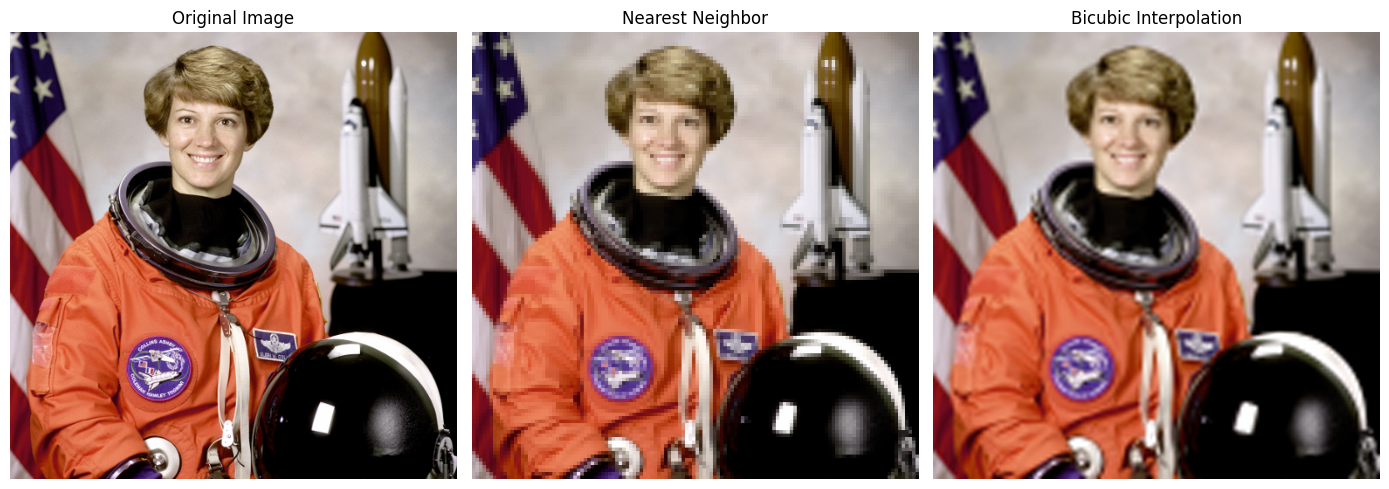

In [2]:

from skimage import data
import cv2
import matplotlib.pyplot as plt

# 1. Load a sample image
original = data.astronaut()

# 2. Reduce its resolution to simulate a low-resolution image
height, width = original.shape[:2]

low_res = cv2.resize(
    original,
    (width // 4, height // 4),
    interpolation=cv2.INTER_AREA
)

# 3. Reconstruct the image using two traditional methods
nearest = cv2.resize(
    low_res, (width, height),
    interpolation=cv2.INTER_NEAREST
)

bicubic = cv2.resize(
    low_res, (width, height),
    interpolation=cv2.INTER_CUBIC
)

# 4. Display the comparison
plt.figure(figsize=(14, 5))

images = [
    (original, "Original Image"),
    (nearest, "Nearest Neighbor"),
    (bicubic, "Bicubic Interpolation")
]

for i, (image, title) in enumerate(images, 1):
    plt.subplot(1, 3, i)
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [3]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Compare each reconstructed image with the original
for name, image in [
    ("Nearest Neighbor", nearest),
    ("Bicubic", bicubic)
]:
    psnr = peak_signal_noise_ratio(
        original, image, data_range=255
    )

    ssim = structural_similarity(
        original, image,
        channel_axis=2,
        data_range=255
    )

    print(f"{name}:")
    print(f"  PSNR: {psnr:.2f} dB")
    print(f"  SSIM: {ssim:.4f}")
    print()


Nearest Neighbor:
  PSNR: 23.40 dB
  SSIM: 0.7834

Bicubic:
  PSNR: 25.57 dB
  SSIM: 0.8393



In [6]:
#CIFAR
import os
import certifi

# Tell Python where to find an updated certificate bundle
os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

from torchvision import datasets, transforms

# Use the alternate CIFAR-10 mirror
datasets.CIFAR10.url = (
    "https://data.brainchip.com/dataset-mirror/cifar10/"
    "cifar-10-python.tar.gz"
)

transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))


Training images: 50000
Testing images: 10000


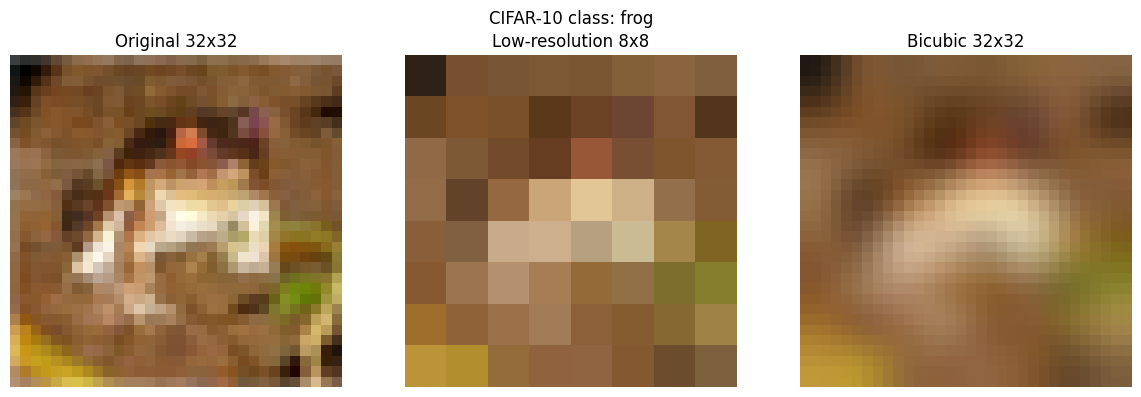

Bicubic PSNR: 20.60 dB
Bicubic SSIM: 0.5674


In [7]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

# Get one image from our training dataset
image, label = train_dataset[0]

# Add a batch dimension: [3, 32, 32] -> [1, 3, 32, 32]
image_batch = image.unsqueeze(0)

# Reduce resolution from 32x32 to 8x8
with torch.no_grad():
    low_res = F.interpolate(
        image_batch,
        size=(8, 8),
        mode="area"
    )

    # Enlarge the image back to 32x32 using bicubic
    bicubic = F.interpolate(
        low_res,
        size=(32, 32),
        mode="bicubic",
        align_corners=False
    ).clamp(0, 1)[0]

# Convert tensors into images for display
original_img = image.permute(1, 2, 0).numpy()
low_res_img = low_res[0].permute(1, 2, 0).numpy()
bicubic_img = bicubic.permute(1, 2, 0).numpy()

# Display the comparison
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(original_img, interpolation="nearest")
axes[0].set_title("Original 32x32")

axes[1].imshow(low_res_img, interpolation="nearest")
axes[1].set_title("Low-resolution 8x8")

axes[2].imshow(bicubic_img)
axes[2].set_title("Bicubic 32x32")

for ax in axes:
    ax.axis("off")

plt.suptitle(f"CIFAR-10 class: {train_dataset.classes[label]}")
plt.tight_layout()
plt.show()

# Measure reconstruction quality
psnr = peak_signal_noise_ratio(
    original_img, bicubic_img, data_range=1.0
)

ssim = structural_similarity(
    original_img, bicubic_img,
    channel_axis=2,
    data_range=1.0
)

print(f"Bicubic PSNR: {psnr:.2f} dB")
print(f"Bicubic SSIM: {ssim:.4f}")


In [8]:
#CNN
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

# Use your RTX 4060 if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class ImageEnhancementCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=9, padding=4),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 32, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 3, kernel_size=5, padding=2)
        )

    def forward(self, x):
        # Predict corrections to the bicubic image
        correction = self.layers(x)

        return (x + correction).clamp(0, 1)


# Create our model
model = ImageEnhancementCNN().to(device)

# Prepare data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print("Device:", device)
print("Model created successfully!")
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))


Device: cuda
Model created successfully!
Training batches: 391
Testing batches: 79


In [11]:

from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

class SuperResolutionDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        # Ground-truth original image
        original, _ = self.base_dataset[index]

        # Downsample: 32x32 -> 8x8
        small = F.interpolate(
            original.unsqueeze(0),
            size=(8, 8),
            mode="area"
        )

        # Bicubic reconstruction: 8x8 -> 32x32
        bicubic = F.interpolate(
            small,
            size=(32, 32),
            mode="bicubic",
            align_corners=False
        ).squeeze(0).clamp(0, 1)

        # Input is bicubic; target is original
        return bicubic, original


# Create image-pair datasets
train_pairs = SuperResolutionDataset(train_dataset)
test_pairs = SuperResolutionDataset(test_dataset)

# Replace the old classification data loaders
train_loader = DataLoader(
    train_pairs,
    batch_size=128,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_pairs,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

# Verify the new loaders
inputs, targets = next(iter(train_loader))

print("Input shape:", inputs.shape)
print("Target shape:", targets.shape)
print("Shapes match:", inputs.shape == targets.shape)


Input shape: torch.Size([128, 3, 32, 32])
Target shape: torch.Size([128, 3, 32, 32])
Shapes match: True


In [12]:
#CNN vs Bicubic
import numpy as np
import torch
from skimage.metrics import structural_similarity

model.eval()

bicubic_psnr_values = []
cnn_psnr_values = []
bicubic_ssim_values = []
cnn_ssim_values = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        # CNN reconstruction
        predictions = model(inputs)

        # Per-image MSE
        bicubic_mse = ((inputs - targets) ** 2).mean(dim=(1, 2, 3))
        cnn_mse = ((predictions - targets) ** 2).mean(dim=(1, 2, 3))

        # PSNR (higher is better)
        bicubic_psnr = 10 * torch.log10(
            1.0 / bicubic_mse.clamp(min=1e-10)
        )
        cnn_psnr = 10 * torch.log10(
            1.0 / cnn_mse.clamp(min=1e-10)
        )

        bicubic_psnr_values.extend(bicubic_psnr.cpu().tolist())
        cnn_psnr_values.extend(cnn_psnr.cpu().tolist())

        # Convert to NumPy images: NCHW -> NHWC
        bicubic_np = inputs.cpu().numpy().transpose(0, 2, 3, 1)
        predictions_np = predictions.cpu().numpy().transpose(0, 2, 3, 1)
        targets_np = targets.cpu().numpy().transpose(0, 2, 3, 1)

        # Per-image SSIM
        for i in range(len(targets_np)):
            bicubic_ssim_values.append(
                structural_similarity(
                    targets_np[i],
                    bicubic_np[i],
                    channel_axis=2,
                    data_range=1.0
                )
            )

            cnn_ssim_values.append(
                structural_similarity(
                    targets_np[i],
                    predictions_np[i],
                    channel_axis=2,
                    data_range=1.0
                )
            )

print("Results on", len(test_dataset), "test images")
print("-" * 42)
print(f"Bicubic PSNR: {np.mean(bicubic_psnr_values):.2f} dB")
print(f"CNN PSNR:     {np.mean(cnn_psnr_values):.2f} dB")
print()
print(f"Bicubic SSIM: {np.mean(bicubic_ssim_values):.4f}")
print(f"CNN SSIM:     {np.mean(cnn_ssim_values):.4f}")


Results on 10000 test images
------------------------------------------
Bicubic PSNR: 21.29 dB
CNN PSNR:     20.60 dB

Bicubic SSIM: 0.6480
CNN SSIM:     0.6347


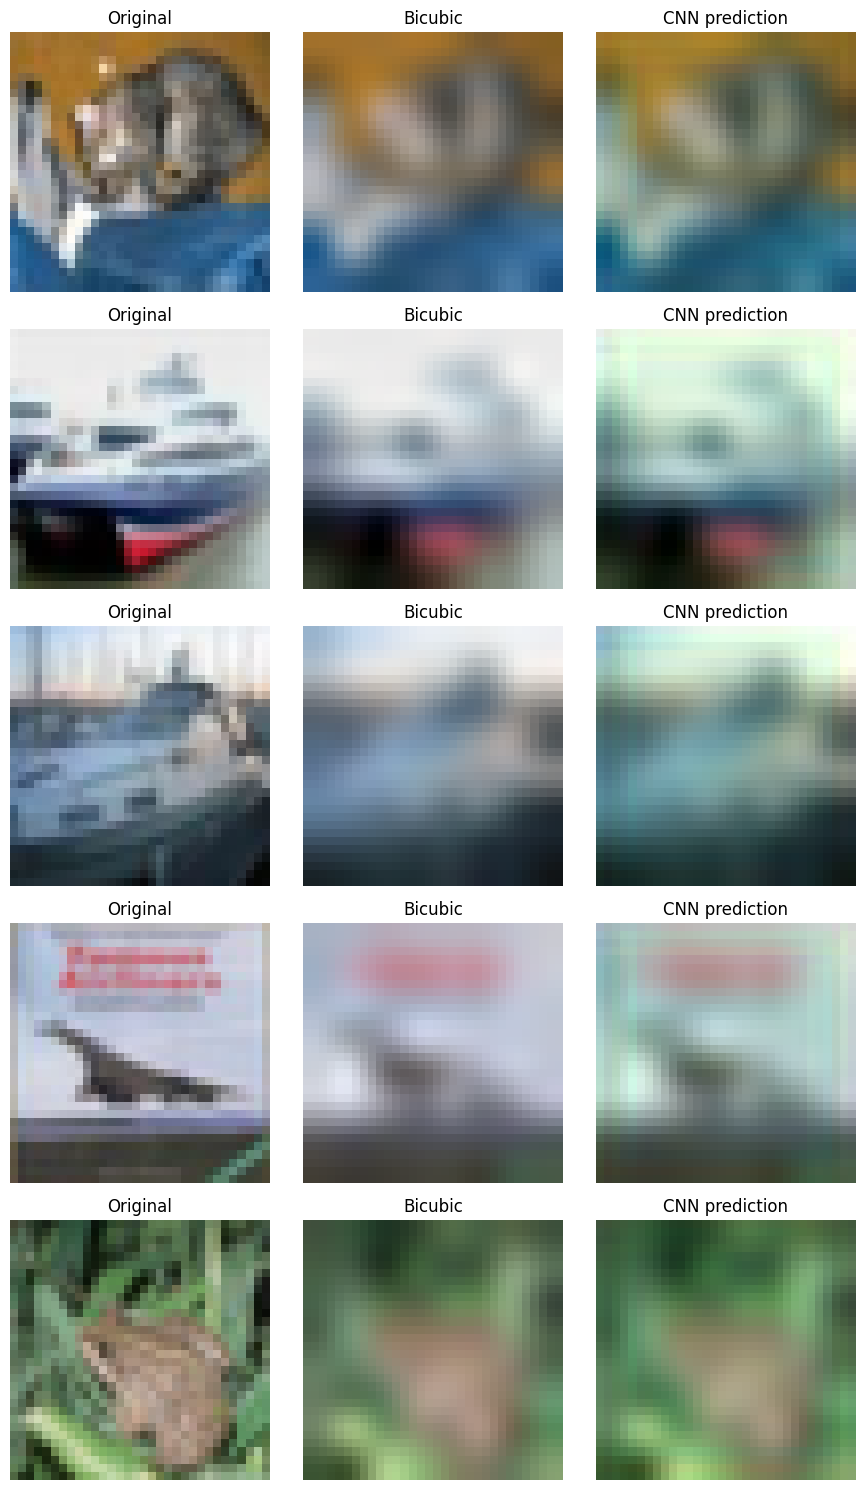

In [13]:

import matplotlib.pyplot as plt
import torch

model.eval()

# Display five test images
fig, axes = plt.subplots(5, 3, figsize=(9, 15))

with torch.no_grad():
    for i in range(5):
        bicubic_img, original_img = test_pairs[i]

        prediction = model(
            bicubic_img.unsqueeze(0).to(device)
        ).cpu().squeeze(0)

        images = [
            (original_img, "Original"),
            (bicubic_img, "Bicubic"),
            (prediction, "CNN prediction")
        ]

        for j, (img, title) in enumerate(images):
            axes[i, j].imshow(img.permute(1, 2, 0))
            axes[i, j].set_title(title)
            axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [14]:
#improve cnn
import torch
import torch.nn as nn

class ImageEnhancementCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=9, padding=4),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 32, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 3, kernel_size=5, padding=2)
        )

        # Start by predicting zero corrections
        final_layer = self.layers[-1]
        nn.init.zeros_(final_layer.weight)
        nn.init.zeros_(final_layer.bias)

    def forward(self, x):
        correction = self.layers(x)
        return (x + correction).clamp(0, 1)


# Create a fresh model and reset the optimizer
model = ImageEnhancementCNN().to(device)

criterion = nn.L1Loss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Verify that the untrained model initially preserves bicubic
inputs, targets = next(iter(train_loader))
inputs = inputs.to(device)

with torch.no_grad():
    predictions = model(inputs)

print("Maximum initial difference:",
      (predictions - inputs).abs().max().item())


Maximum initial difference: 0.0


In [15]:
#train
epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        predictions = model(inputs)
        loss = criterion(predictions, targets)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"| Average L1 loss: {average_loss:.5f}"
    )

print("Improved CNN training complete!")


Epoch 1/5 | Average L1 loss: 0.06073
Epoch 2/5 | Average L1 loss: 0.05932
Epoch 3/5 | Average L1 loss: 0.05891
Epoch 4/5 | Average L1 loss: 0.05870
Epoch 5/5 | Average L1 loss: 0.05852
Improved CNN training complete!


In [16]:
#evaluate

import numpy as np
import torch
from skimage.metrics import structural_similarity

model.eval()

bicubic_psnr_values = []
cnn_psnr_values = []
bicubic_ssim_values = []
cnn_ssim_values = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        predictions = model(inputs)

        # Calculate PSNR
        bicubic_mse = ((inputs - targets) ** 2).mean(dim=(1, 2, 3))
        cnn_mse = ((predictions - targets) ** 2).mean(dim=(1, 2, 3))

        bicubic_psnr = 10 * torch.log10(
            1.0 / bicubic_mse.clamp(min=1e-10)
        )
        cnn_psnr = 10 * torch.log10(
            1.0 / cnn_mse.clamp(min=1e-10)
        )

        bicubic_psnr_values.extend(bicubic_psnr.cpu().tolist())
        cnn_psnr_values.extend(cnn_psnr.cpu().tolist())

        # Convert images from NCHW to NHWC
        bicubic_np = inputs.cpu().numpy().transpose(0, 2, 3, 1)
        cnn_np = predictions.cpu().numpy().transpose(0, 2, 3, 1)
        targets_np = targets.cpu().numpy().transpose(0, 2, 3, 1)

        # Calculate SSIM
        for i in range(len(targets_np)):
            bicubic_ssim_values.append(
                structural_similarity(
                    targets_np[i], bicubic_np[i],
                    channel_axis=2, data_range=1.0
                )
            )

            cnn_ssim_values.append(
                structural_similarity(
                    targets_np[i], cnn_np[i],
                    channel_axis=2, data_range=1.0
                )
            )

print("Results on", len(test_dataset), "test images")
print("-" * 42)
print(f"Bicubic PSNR: {np.mean(bicubic_psnr_values):.2f} dB")
print(f"CNN PSNR:     {np.mean(cnn_psnr_values):.2f} dB")
print(f"Bicubic SSIM: {np.mean(bicubic_ssim_values):.4f}")
print(f"CNN SSIM:     {np.mean(cnn_ssim_values):.4f}")


Results on 10000 test images
------------------------------------------
Bicubic PSNR: 21.29 dB
CNN PSNR:     21.85 dB
Bicubic SSIM: 0.6480
CNN SSIM:     0.6963


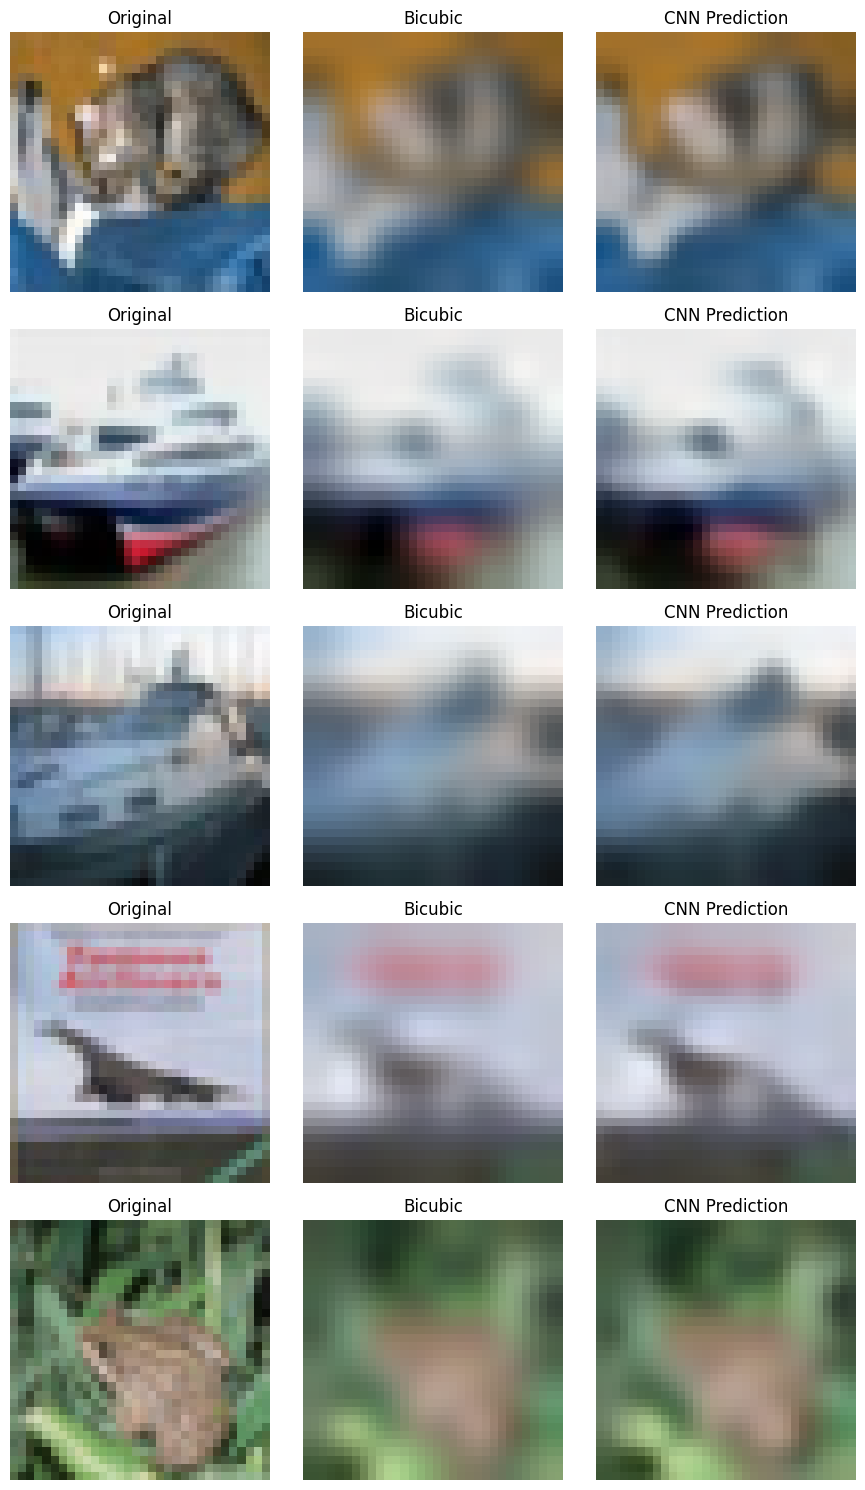

In [17]:
model.eval()

fig, axes = plt.subplots(5, 3, figsize=(9, 15))

with torch.no_grad():
    for i in range(5):
        bicubic_img, original_img = test_pairs[i]

        prediction = model(
            bicubic_img.unsqueeze(0).to(device)
        ).cpu().squeeze(0)

        images = [
            (original_img, "Original"),
            (bicubic_img, "Bicubic"),
            (prediction, "CNN Prediction")
        ]

        for j, (img, title) in enumerate(images):
            axes[i, j].imshow(img.permute(1, 2, 0))
            axes[i, j].set_title(title)
            axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [18]:

# Keep our existing model and learned weights
# Reduce the learning rate for finer adjustments
for param_group in optimizer.param_groups:
    param_group["lr"] = 0.0003

additional_epochs = 10

for epoch in range(additional_epochs):
    model.train()
    total_loss = 0.0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        predictions = model(inputs)
        loss = criterion(predictions, targets)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Additional epoch {epoch + 1}/{additional_epochs} "
        f"| L1 Loss: {average_loss:.5f}"
    )

print("Further training complete!")


Additional epoch 1/10 | L1 Loss: 0.05822
Additional epoch 2/10 | L1 Loss: 0.05812
Additional epoch 3/10 | L1 Loss: 0.05805
Additional epoch 4/10 | L1 Loss: 0.05799
Additional epoch 5/10 | L1 Loss: 0.05794
Additional epoch 6/10 | L1 Loss: 0.05788
Additional epoch 7/10 | L1 Loss: 0.05784
Additional epoch 8/10 | L1 Loss: 0.05778
Additional epoch 9/10 | L1 Loss: 0.05773
Additional epoch 10/10 | L1 Loss: 0.05769
Further training complete!


In [19]:
model.eval()

bicubic_psnr_values = []
cnn_psnr_values = []
bicubic_ssim_values = []
cnn_ssim_values = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        predictions = model(inputs)

        # PSNR
        bicubic_mse = ((inputs - targets) ** 2).mean(dim=(1, 2, 3))
        cnn_mse = ((predictions - targets) ** 2).mean(dim=(1, 2, 3))

        bicubic_psnr = 10 * torch.log10(1.0 / bicubic_mse.clamp(min=1e-10))
        cnn_psnr = 10 * torch.log10(1.0 / cnn_mse.clamp(min=1e-10))

        bicubic_psnr_values.extend(bicubic_psnr.cpu().tolist())
        cnn_psnr_values.extend(cnn_psnr.cpu().tolist())

        # SSIM
        bicubic_np = inputs.cpu().numpy().transpose(0, 2, 3, 1)
        cnn_np = predictions.cpu().numpy().transpose(0, 2, 3, 1)
        targets_np = targets.cpu().numpy().transpose(0, 2, 3, 1)

        for i in range(len(targets_np)):
            bicubic_ssim_values.append(
                structural_similarity(
                    targets_np[i], bicubic_np[i],
                    channel_axis=2, data_range=1.0
                )
            )
            cnn_ssim_values.append(
                structural_similarity(
                    targets_np[i], cnn_np[i],
                    channel_axis=2, data_range=1.0
                )
            )

print("Results on", len(test_dataset), "test images")
print("-" * 42)
print(f"Bicubic PSNR: {np.mean(bicubic_psnr_values):.2f} dB")
print(f"CNN PSNR:     {np.mean(cnn_psnr_values):.2f} dB")
print(f"Bicubic SSIM: {np.mean(bicubic_ssim_values):.4f}")
print(f"CNN SSIM:     {np.mean(cnn_ssim_values):.4f}")

Results on 10000 test images
------------------------------------------
Bicubic PSNR: 21.29 dB
CNN PSNR:     21.93 dB
Bicubic SSIM: 0.6480
CNN SSIM:     0.6994


In [20]:
# Save our trained CNN
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "architecture": "ImageEnhancementCNN",
        "input_size": 32,
        "scale_factor": 4
    },
    "image_enhancement_cnn.pth"
)

print("Model saved successfully!")
print("File: image_enhancement_cnn.pth")

Model saved successfully!
File: image_enhancement_cnn.pth


In [21]:

%%writefile app.py
import streamlit as st
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from PIL import Image, ImageOps

st.set_page_config(
    page_title="AI Image Enhancement Studio",
    page_icon="🖼️",
    layout="wide"
)

class ImageEnhancementCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=9, padding=4),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 3, kernel_size=5, padding=2)
        )

        nn.init.zeros_(self.layers[-1].weight)
        nn.init.zeros_(self.layers[-1].bias)

    def forward(self, x):
        correction = self.layers(x)
        return (x + correction).clamp(0, 1)


@st.cache_resource
def load_model():
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    checkpoint = torch.load(
        "image_enhancement_cnn.pth",
        map_location=device,
        weights_only=True
    )

    model = ImageEnhancementCNN().to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    return model, device


st.title("🖼️ AI Image Enhancement Studio")
st.write(
    "Compare traditional bicubic interpolation with "
    "our CNN-based image reconstruction model."
)

st.warning(
    "Experimental prototype: the CNN was trained on CIFAR-10 "
    "images at 32×32 resolution. Uploaded images are center-cropped "
    "to a square and reduced to 32×32, then to 8×8 before reconstruction. "
    "Results on ordinary photographs may be poor."
)

uploaded_file = st.file_uploader(
    "Upload an image",
    type=["jpg", "jpeg", "png", "webp"]
)

if uploaded_file is not None:
    try:
        original = Image.open(uploaded_file).convert("RGB")

        # Prepare a square 32x32 input for our trained model
        original_32 = ImageOps.fit(
            original,
            (32, 32),
            method=Image.Resampling.LANCZOS
        )

        array = np.array(original_32, dtype=np.float32) / 255.0

        tensor = (
            torch.from_numpy(array)
            .permute(2, 0, 1)
            .unsqueeze(0)
        )

        model, device = load_model()
        tensor = tensor.to(device)

        with torch.no_grad():
            # Simulate low resolution: 32x32 -> 8x8
            low_res = F.interpolate(
                tensor,
                size=(8, 8),
                mode="area"
            )

            # Traditional bicubic reconstruction: 8x8 -> 32x32
            bicubic = F.interpolate(
                low_res,
                size=(32, 32),
                mode="bicubic",
                align_corners=False
            ).clamp(0, 1)

            # Our trained CNN reconstruction
            enhanced = model(bicubic)

        def to_pil(image_tensor):
            image_array = (
                image_tensor[0]
                .detach()
                .cpu()
                .permute(1, 2, 0)
                .numpy()
            )

            image_array = np.clip(
                image_array * 255, 0, 255
            ).round().astype(np.uint8)

            return Image.fromarray(image_array)

        low_res_img = to_pil(low_res)
        bicubic_img = to_pil(bicubic)
        enhanced_img = to_pil(enhanced)

        # Enlarge previews for display only; model output stays 32x32
        preview_size = (256, 256)

        original_preview = original_32.resize(
            preview_size, Image.Resampling.NEAREST
        )
        low_res_preview = low_res_img.resize(
            preview_size, Image.Resampling.NEAREST
        )
        bicubic_preview = bicubic_img.resize(
            preview_size, Image.Resampling.NEAREST
        )
        enhanced_preview = enhanced_img.resize(
            preview_size, Image.Resampling.NEAREST
        )

        st.subheader("Image comparison")

        col1, col2, col3 = st.columns(3)

        with col1:
            st.image(original_preview, caption="Input (32×32 crop)")
        with col2:
            st.image(bicubic_preview, caption="Bicubic reconstruction")
        with col3:
            st.image(enhanced_preview, caption="CNN reconstruction")

        with st.expander("View the 8×8 low-resolution input"):
            st.image(low_res_preview, caption="Low-resolution image")

        st.caption(
            "Previews are enlarged for visibility. The model's actual "
            "output is 32×32 pixels, not a full-resolution restoration."
        )

        # Download the CNN's actual 32x32 result
        from io import BytesIO

        buffer = BytesIO()
        enhanced_img.save(buffer, format="PNG")

        st.download_button(
            "Download CNN result (32×32 PNG)",
            data=buffer.getvalue(),
            file_name="cnn_enhanced.png",
            mime="image/png"
        )

    except FileNotFoundError:
        st.error(
            "Model file not found. Make sure "
            "image_enhancement_cnn.pth is in the same folder as app.py."
        )
    except Exception as error:
        st.error(f"Something went wrong: {error}")


Writing app.py


In [22]:
%run -m streamlit run app.py


      Welcome to Streamlit!

      If you'd like to receive helpful onboarding emails, news, offers, promotions,
      and the occasional swag, please enter your email address below. Otherwise,
      leave this field blank.

      Email: [0

m 



  You can find our privacy policy at https://streamlit.io/privacy-policy

  Summary:
  - This open source library collects usage statistics.
  - We cannot see and do not store information contained inside Streamlit apps,
    such as text, charts, images, etc.
  - Telemetry data is stored in servers in the United States.
  - If you'd like to opt out, add the following to %userprofile%/.streamlit/config.toml,
    creating that file if necessary:

    [browser]
    gatherUsageStats = false


  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://10.190.232.218:8501



In [23]:
%pwd
%ls

 Volume in drive C is Windows-SSD
 Volume Serial Number is EC73-769D

 Directory of C:\Users\LENOVO

13-10-2026  10.09 PM    <DIR>          .
09-06-2025  12.00 AM    <DIR>          ..
12-07-2026  01.13 AM    <DIR>          .anaconda
28-09-2026  09.13 PM    <DIR>          .android
28-06-2026  12.54 PM    <DIR>          .cache
13-10-2026  05.59 PM    <DIR>          .codex
09-01-2026  09.35 PM    <DIR>          .conda
06-08-2025  08.57 PM    <DIR>          .config
11-09-2026  07.40 PM    <DIR>          .copilot
15-09-2026  07.33 PM    <DIR>          .cursor
07-05-2025  11.27 PM    <DIR>          .eclipse
12-09-2026  02.24 AM                63 .gitconfig
07-06-2025  08.59 PM    <DIR>          .idlerc
13-10-2026  08.15 PM    <DIR>          .ipynb_checkpoints
18-12-2025  10.22 PM    <DIR>          .ipython
18-12-2025  11.01 PM    <DIR>          .jupyter
16-06-2026  09.54 PM    <DIR>          .keras
16-10-2025  12.26 AM    <DIR>          .matplotlib
24-10-2024  11.59 AM    <DIR>          .ms-

In [25]:
from pathlib import Path

# Show the folder where Jupyter is running
folder = Path.cwd()
print("Current folder:", folder)

# Check whether our project files are here
for name in [
    "app.py",
    "image_enhancement_cnn.pth",
    "ai_enhancement_project.ipynb"
]:
    path = folder / name
    print(name, "✅ FOUND" if path.exists() else "❌ Not found here")

# Show other files in this folder
print("\nFiles in current folder:")
for path in list(folder.iterdir())[:25]:
    print(path.name)

Current folder: C:\Users\LENOVO
app.py ✅ FOUND
image_enhancement_cnn.pth ✅ FOUND
ai_enhancement_project.ipynb ✅ FOUND

Files in current folder:
-1.14-windows.xml
.anaconda
.android
.cache
.codex
.conda
.config
.copilot
.cursor
.eclipse
.gitconfig
.idlerc
.ipynb_checkpoints
.ipython
.jupyter
.keras
.matplotlib
.ms-ad
.p2
.streamlit
.thumbnails
.vscode
.vscode-shared
850Uwind - 850Uwind.csv
adv.csv
